# 🛰️ OrbiTerra — Análise de dados e Machine Learning

**Notebook complementar** da POC (Global Solution 2026.1 · FIAP). Ele reaproveita os módulos
de `src/` (`simulador_dados.py` e `treino_modelo.py`) — **fonte única de verdade** — e mostra a
narrativa de análise com os gráficos renderizados *inline*:

1. Geração e visão geral dos dados (satélite + clima + ESP32)
2. Análise exploratória (EDA)
3. Engenharia de variáveis e treino dos modelos (**Modelo A** só satélite+clima × **Modelo B** +ESP32)
4. Conclusão

> Os apps interativos (emulador ESP32 e painel Streamlit) ficam nos scripts `.py`.

In [1]:
import sys, os
sys.path.insert(0, 'src')                 # importa os módulos do projeto
import numpy as np
import pandas as pd

import simulador_dados as sim
from treino_modelo import (
    engenharia, split_temporal, treina_cenario,
    FEATS_SATELITE_CLIMA, FEATS_ESP32, NOMES_RISCO,
)
print('Módulos do projeto carregados com sucesso.')

Módulos do projeto carregados com sucesso.


In [2]:
# treino_modelo importa matplotlib em modo Agg (p/ salvar PNG nos scripts);
# aqui reativamos o modo inline para ver os gráficos dentro do notebook.
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 110

## 1. Geração e visão geral dos dados

O simulador gera ~3 anos de dados diários a partir de um **balanço hídrico do solo** (o *alvo*),
e expõe as variáveis observáveis: satélite (NDVI/EVI/LST), clima (chuva/temperatura) e ESP32
(umidade do solo, temp/umidade do ar).

In [3]:
df_raw = sim.simular()
print('Formato:', df_raw.shape)
df_raw.head()

Formato: (1089, 12)


,data,lat,lon,ndvi,evi,lst,precip_mm,temp_ar,umidade_solo,temp_ar_esp,umidade_ar,risco_7d
0,2022-01-07,-20.78,-47.3,0.712,0.483,36.2,0.0,25.7,63.5,25.3,63.2,1
1,2022-01-08,-20.78,-47.3,0.712,0.483,37.1,0.0,25.0,52.6,24.2,68.2,1
2,2022-01-09,-20.78,-47.3,0.712,0.483,35.8,0.0,25.4,49.1,24.4,65.1,1
3,2022-01-10,-20.78,-47.3,0.712,0.483,37.3,0.0,24.1,59.3,24.1,61.6,1
4,2022-01-11,-20.78,-47.3,0.712,0.483,39.1,0.0,26.9,38.6,26.5,62.9,1


In [4]:
# Estatística descritiva das principais variáveis
df_raw[['ndvi', 'lst', 'precip_mm', 'temp_ar', 'umidade_solo', 'umidade_ar']].describe().round(2)

,ndvi,lst,precip_mm,temp_ar,umidade_solo,umidade_ar
count,1089.00,1089.00,1089.00,1089.00,1089.00,1089.00
mean,0.57,32.05,3.62,20.94,43.16,67.89
std,0.17,2.73,8.46,3.58,40.45,9.28
min,0.34,23.80,0.00,11.00,0.00,41.10
25%,0.40,30.20,0.00,17.80,2.50,60.50
50%,0.53,32.00,0.00,20.90,32.30,66.90
75%,0.75,33.90,2.50,23.90,87.40,76.10
max,0.82,40.20,62.50,29.30,100.00,92.20


In [5]:
# Distribuição do rótulo (risco dos próximos 7 dias)
dist = df_raw['risco_7d'].map(NOMES_RISCO).value_counts().reindex(['Baixo', 'Médio', 'Alto'])
dist

risco_7d
Baixo    414
Médio    112
Alto     563
Name: count, dtype: int64

## 2. Análise exploratória (EDA)

A distribuição mostra que a estação seca domina (risco Alto frequente) — o modelo terá que superar
o *baseline* da classe majoritária. Em seguida, o ponto central do projeto: **a umidade do solo
(ESP32) cai ANTES do NDVI (satélite)**.

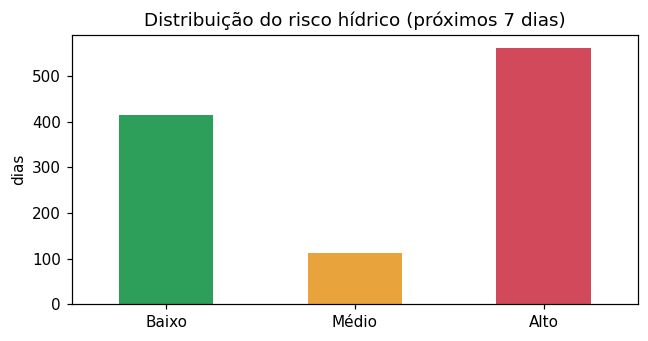

In [6]:
cores = {'Baixo': '#2e9e5b', 'Médio': '#e8a33d', 'Alto': '#d1495b'}
ax = dist.plot.bar(color=[cores[k] for k in dist.index], figsize=(6, 3.2))
ax.set_title('Distribuição do risco hídrico (próximos 7 dias)')
ax.set_ylabel('dias'); ax.set_xlabel('')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

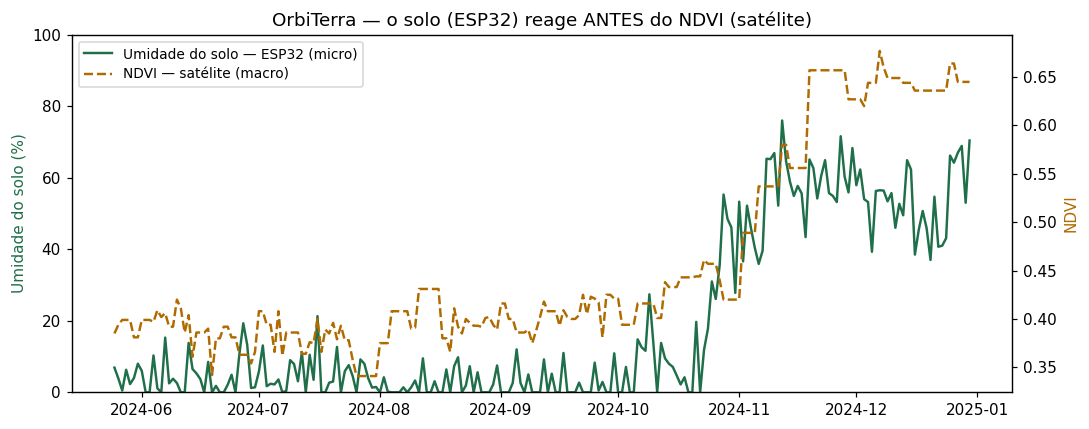

In [7]:
jan = df_raw.iloc[-220:]   # ~últimos 7 meses
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(jan['data'], jan['umidade_solo'], color='#1f6f4a', lw=1.6,
         label='Umidade do solo — ESP32 (micro)')
ax1.set_ylabel('Umidade do solo (%)', color='#1f6f4a'); ax1.set_ylim(0, 100)
ax2 = ax1.twinx()
ax2.plot(jan['data'], jan['ndvi'], '--', color='#b06b00', lw=1.6,
         label='NDVI — satélite (macro)')
ax2.set_ylabel('NDVI', color='#b06b00')
ax1.set_title('OrbiTerra — o solo (ESP32) reage ANTES do NDVI (satélite)')
linhas = ax1.get_lines() + ax2.get_lines()
ax1.legend(linhas, [l.get_label() for l in linhas], loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

## 3. Engenharia de variáveis e treino dos modelos

Criamos variáveis de memória e tendência (chuva acumulada, dias sem chuva, média/tendência da
umidade do solo, sazonalidade). Treinamos **Random Forest** e **XGBoost** em dois cenários, com
**validação temporal** (treina no passado, testa no futuro).

In [8]:
df = engenharia(df_raw)
treino, teste = split_temporal(df)
print(f'Treino: {len(treino)} dias | Teste: {len(teste)} dias '
      f'(corte temporal em {teste["data"].min().date()})')

Treino: 816 dias | Teste: 273 dias (corte temporal em 2024-04-02)


In [9]:
# Modelo A = satélite + clima ; Modelo B = A + ESP32
res_a, yte = treina_cenario(treino, teste, FEATS_SATELITE_CLIMA, 'A')
res_b, _   = treina_cenario(treino, teste, FEATS_SATELITE_CLIMA + FEATS_ESP32, 'B')

baseline = yte.value_counts().max() / len(yte)
print(f'Baseline (classe majoritária): {baseline:.1%}')

tabela = pd.DataFrame([
    {'Algoritmo': a,
     'A (satélite+clima)': f"{res_a[a]['acc']:.1%}",
     'B (+ESP32)':         f"{res_b[a]['acc']:.1%}",
     'Ganho':              f"+{(res_b[a]['acc'] - res_a[a]['acc']) * 100:.1f} pt",
     'F1-macro (B)':       f"{res_b[a]['f1']:.3f}"}
    for a in res_a
])
tabela

Baseline (classe majoritária): 68.9%


,Algoritmo,A (satélite+clima),B (+ESP32),Ganho,F1-macro (B)
0,Random Forest,83.9%,97.4%,+13.6 pt,0.916
1,XGBoost,78.8%,93.0%,+14.3 pt,0.884


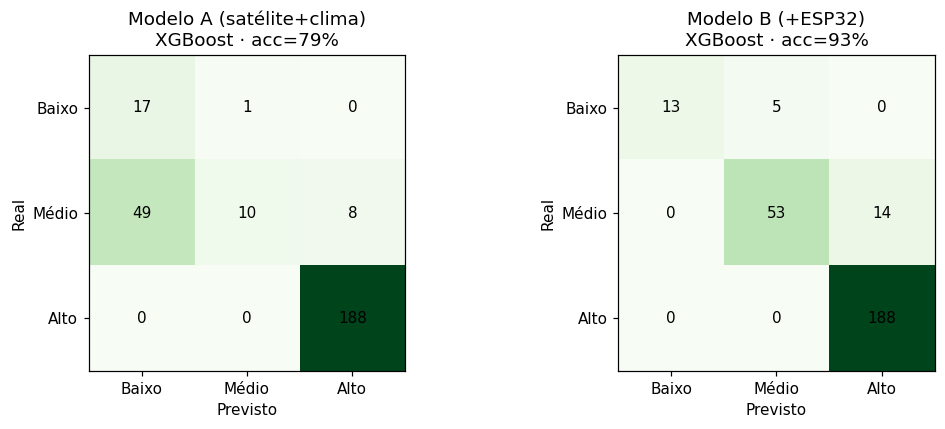

In [10]:
# Matriz de confusão: o Modelo A subestima o risco; o B corrige
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, res, titulo in [(axes[0], res_a['XGBoost'], 'Modelo A (satélite+clima)'),
                        (axes[1], res_b['XGBoost'], 'Modelo B (+ESP32)')]:
    cm = confusion_matrix(yte, res['pred'], labels=[0, 1, 2])
    ax.imshow(cm, cmap='Greens')
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(NOMES_RISCO.values()); ax.set_yticklabels(NOMES_RISCO.values())
    ax.set_xlabel('Previsto'); ax.set_ylabel('Real')
    ax.set_title(f"{titulo}\nXGBoost · acc={res['acc']:.0%}")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center')
plt.tight_layout(); plt.show()

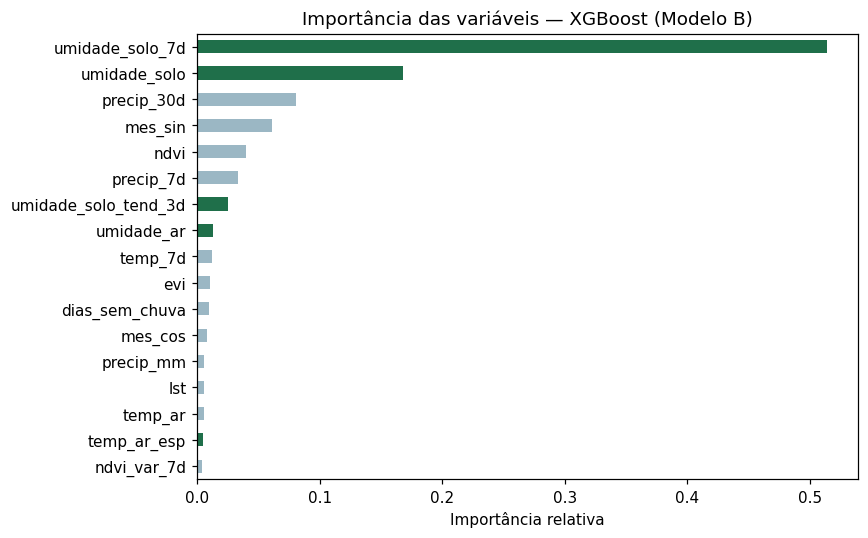

In [11]:
# Importância das variáveis — os sinais do ESP32 (verde) dominam o topo
modelo = res_b['XGBoost']['modelo']
feats = FEATS_SATELITE_CLIMA + FEATS_ESP32
imp = pd.Series(modelo.feature_importances_, index=feats).sort_values()
cores_imp = ['#1f6f4a' if f in FEATS_ESP32 else '#9bb7c4' for f in imp.index]
imp.plot.barh(color=cores_imp, figsize=(8, 5),
              title='Importância das variáveis — XGBoost (Modelo B)')
plt.xlabel('Importância relativa'); plt.tight_layout(); plt.show()

## 4. Conclusão

- **O sensor de campo se paga:** adicionar o ESP32 (Modelo B) eleva a acurácia em ambos os
  algoritmos, com validação temporal.
- A **umidade do solo** (`umidade_solo_7d`, `umidade_solo`) é a variável **mais importante** do
  modelo — confirma a tese de que o indicador antecipado vem do campo, não do satélite.
- Mais do que acurácia, o ganho é de **segurança**: o Modelo A troca "Médio" por "Baixo"
  (subestima o risco), e o Modelo B corrige esse erro perigoso.

> Próximo passo (fora da POC): substituir o simulador por dados reais via Google Earth Engine
> (Sentinel-2 / MODIS / CHIRPS) e instalar o ESP32 físico no talhão.